# H11：相同训练样本下的常见模型对照

研究结论与采用决定由 [卷宗 H11](README.md#h11) 维护。本 Notebook 保存固定算法对照的运行事实。
沿用 H10 的102日、507,397个训练股票日，T+1/3/5，日频7列与日频+L2共39列。
验证27日（2026-07-17至08-24）、评估17日（08-26至09-17）均已查看；本轮检验固定算法与参数组合的敏感性，不是独立模型选择测试。

**运行摘要。** 15种固定配置、90组完整输出：84组新结果及6组原HGB锚点；所有拟合完成且未报告不收敛。
共19,798,650条预测、3,960份模型日Top50名单及指标通过独立复算或保存模型重载核验。
主要5日区块统计下，只有逻辑回归T+1与日期加权KNN T+1同时达到两段平均L2增量≥2个百分点、单侧95%下界>0；
主口径经45个模型/期限比较校正后，没有组合两段同时通过。预定10日区块敏感性下，逻辑回归与KNN T+1会通过校正；区块口径敏感，不能事后替换主口径。T+3/T+5在两种区块设置下均没有组合通过原两段门槛。

评估期T+1，KNN的增量为+6.33个百分点（29.65%→35.98%），传统GBDT为+1.06个百分点（39.89%→40.95%）；
这两个数字分别反映条件增量与最终绝对命中率。MLP的T+3/T+5平均增量为+1.97/+2.50个百分点，名义95%区间都跨过零。
每种算法仅一套预定参数、一个seed，算法、容量和正则化设置未被进一步拆开。新独立日期为0，原H08前向候选保持不变。

[完整90行对照表（含日频、日频加L2、随机期望与区间）](/home/wsw/app/research-evidence/subscription-model-comparison-2026-10-08-stutfi_l/完整模型对照.csv)
与[冻结协议、输入及全部证据](/home/wsw/app/research-evidence/subscription-model-comparison-2026-10-08-stutfi_l/)一并保留。
随机项是相同候选池均匀抽取的解析期望，不是一次随机抽签；命中率是Top50进入目标日收益排名前10%的比例，不是盈利概率或收益率。

**执行与展示。** 9个计算单元顺序执行完成。随后仅修正绘图单元的图例位置和近零值显示，并从保存的汇总表重绘；
拟合、评价和统计代码及结果均未改动。三张PNG已逐图查看；HTML导出的内嵌图片逐字节校验，完整HTML页面未做浏览器视觉检查。
可在浏览器打开[HTML预览](/home/wsw/app/research-evidence/subscription-model-comparison-2026-10-08-stutfi_l/model_comparison.html)，检查完整页面及窄窗口的表格、图像布局。
原完整执行Notebook、绘图重放代码和日志均保留。joblib曾报告一个worker停止警告，原因未确认；78次参数拟合全部返回，90组预测完整，未将缺失或失败结果丢弃。


## 1. 协议、环境和输入

方案在任何替代模型拟合前固定，共15种配置：14个替代配置及原HGB锚点。
全部训练行和日期等权权重相同；特征缺失仍填0.5，不缩放，不以未来标签改变推理候选。
候选参数、资源、统计边界和停止条件见证据目录 protocol.json。
精确恢复使用本次隔离环境 environment/pyproject.toml 和 uv.lock；启动时以 runtime-source 为PYTHONPATH。
复制完整证据到新目录后设置 SUBSCRIPTION_MODELS_EVIDENCE；不得覆盖本次归档或写入正式数据根。

In [1]:
from pathlib import Path
from datetime import datetime, time, date
from zoneinfo import ZoneInfo
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import time as wall_time
import traceback
import warnings

import joblib
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn import config_context
from sklearn.ensemble import AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from IPython.display import display, Image

import src
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils
from src.utils.filesystem import FileSystem

evidence = Path(os.environ.get('SUBSCRIPTION_MODELS_EVIDENCE', '/home/wsw/app/research-evidence/subscription-model-comparison-2026-10-08-stutfi_l'))
assert Path(src.__file__).resolve() == (evidence/'runtime-source/src/__init__.py').resolve()
protocol_bytes = (evidence/'protocol.json').read_bytes()
assert hashlib.sha256(protocol_bytes).hexdigest() == '52310d16f46e8748bc20f322769dd941c47c20a9c95a372ad197bc43cfd46b97'
protocol = json.loads(protocol_bytes)
manifest = json.loads((evidence/'input-manifest.json').read_text())
assert hashlib.sha256((evidence/'input-manifest.json').read_bytes()).hexdigest() == protocol['input_manifest_sha256']
for entry in manifest:
    assert hashlib.sha256((evidence/entry['path']).read_bytes()).hexdigest() == entry['sha256'], entry['path']
source_manifest = json.loads((evidence/'anchor-source-manifest.json').read_text())
for relative, specification in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/relative).read_bytes()).hexdigest() == specification['sha256'], relative
assert hashlib.sha256((evidence/'environment/uv.lock').read_bytes()).hexdigest() == protocol['environment_lock_sha256']
package_names = ['numpy','pandas','pyarrow','scikit-learn','scipy','joblib','threadpoolctl','matplotlib','IPython','xgboost-cpu','lightgbm','catboost']
environment = {'python':platform.python_version(), 'packages':{name:importlib.metadata.version(name) for name in package_names}}
for name, version in json.loads((evidence/'anchor-environment.json').read_text())['packages'].items():
    assert importlib.metadata.version(name)==version, name
(evidence/'environment.json').write_text(json.dumps(environment,indent=2)+'\n')
for folder in ['runs','predictions','models','knn','figures','joblib-temp']:
    (evidence/folder).mkdir(exist_ok=True)
print({'models':len(protocol['models']), 'input_files':len(manifest), 'source_files':len(source_manifest), 'environment':environment})

{'models': 15, 'input_files': 175, 'source_files': 169, 'environment': {'python': '3.13.13', 'packages': {'numpy': '2.5.1', 'pandas': '3.0.2', 'pyarrow': '25.0.0', 'scikit-learn': '1.8.0', 'scipy': '1.16.3', 'joblib': '1.5.3', 'threadpoolctl': '3.6.0', 'matplotlib': '3.10.8', 'IPython': '9.15.0', 'xgboost-cpu': '3.4.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10'}}}


## 2. 精确恢复共同训练行及预测池

只从02-03至07-09的已成熟训练标签建立交集，不使用验证期或评估期标签筛选预测池。
直接与上轮冻结的训练键、日期权重及三个目标逐值比对。训练函数仅收到训练目标；
验证和评估目标只由后面的评价单元读取，不作为早停或校准输入。

In [2]:
keys = ['symbol','trade_date','decision_ts_utc']
files = sorted((evidence/'inputs/fixed/features/previous_day_daily_l2/v1').glob('trade_date=*/data.parquet'))
features = pd.concat([pd.read_parquet(path) for path in files],ignore_index=True)
labels = {h:pd.read_parquet(evidence/f'labels/t{h}.parquet') for h in protocol['horizons']}
for frame in labels.values():
    assert frame[keys].equals(features[keys])
    assert not frame.duplicated(keys).any()
fit_table = pd.read_parquet(evidence/'anchor-models/fit-keys.parquet')
mask = features.trade_date.isin(protocol['common_train_dates'])
for h in protocol['horizons']:
    mask &= labels[h].y_event.notna()
assert features.loc[mask,keys].reset_index(drop=True).equals(fit_table[keys])
assert len(fit_table)==507397 and fit_table.trade_date.nunique()==102
fit_key_hash = hashlib.sha256(pd.util.hash_pandas_object(fit_table[keys],index=True).to_numpy().tobytes()).hexdigest()
assert fit_key_hash==protocol['common_fit_key_sha256']
weights = fit_table.weight.to_numpy(copy=True)
counts = fit_table.groupby('trade_date').symbol.transform('size').to_numpy(dtype=float)
expected_weights = 1/counts
expected_weights /= expected_weights.mean()
np.testing.assert_array_equal(weights,expected_weights)
first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9),date(2026,7,17))
for h in protocol['horizons']:
    np.testing.assert_array_equal(fit_table[f'y_t{h}'].to_numpy(),labels[h].loc[mask,'y_event'].to_numpy())
    assert labels[h].loc[mask,'label_ready_ts'].lt(first_decision).all()
    changed = labels[h].y_event.copy()
    changed.loc[~features.trade_date.isin(protocol['common_train_dates'])] = np.nan
    np.testing.assert_array_equal(changed.loc[mask],fit_table[f'y_t{h}'])
evaluation = features.loc[features.trade_date.isin(protocol['prediction_dates'])].reset_index(drop=True)
assert len(evaluation)==219985 and evaluation.trade_date.nunique()==44
stage_by_date = {day:stage for stage,days in protocol['stages'].items() for day in days}
prediction_keys = evaluation[keys].copy()
prediction_keys['stage'] = prediction_keys.trade_date.map(stage_by_date)
train_arrays = {group:np.ascontiguousarray(features.loc[mask,columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
prediction_arrays = {group:np.ascontiguousarray(evaluation[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
for group in train_arrays:
    assert np.isfinite(train_arrays[group]).all() and np.isfinite(prediction_arrays[group]).all()
    assert np.min(train_arrays[group])>=0 and np.max(train_arrays[group])<=1
print({'train_rows':len(fit_table),'train_days':102,'fit_key_hash':fit_key_hash,'predictions_per_output':len(evaluation)})

{'train_rows': 507397, 'train_days': 102, 'fit_key_hash': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'predictions_per_output': 219985}


## 3. 原HGB锚点恢复

六个HGB模型直接使用上轮共同训练行的保存版本，不再次拟合。
恢复所有219,985行分数；任何不一致都会阻止替代模型试验继续。

In [3]:
fit_records=[]
for h in protocol['horizons']:
    for group,columns in protocol['features'].items():
        saved = pd.read_parquet(evidence/f'anchor-predictions/t{h}-{group}.parquet')
        assert saved[keys].equals(prediction_keys[keys])
        model = joblib.load(evidence/f'anchor-models/t{h}-{group}.joblib')
        with threadpool_limits(limits=1):
            scores = model.predict(evaluation[columns].to_numpy(dtype=float))
        np.testing.assert_array_equal(scores,saved.prediction.to_numpy())
        saved.to_parquet(evidence/f'predictions/hist_gbdt-t{h}-{group}.parquet',index=False)
        fit_records.append({'model':'hist_gbdt','horizon':h,'group':group,'status':'reused','prediction_rows':len(saved),'fit_rows':len(fit_table),'fit_key_sha256':fit_key_hash,'score_type':'probability','warnings':[]})
print('Six anchors recovered exactly:',6*len(evaluation),'scores.')

Six anchors recovered exactly: 1319910 scores.


## 4. 固定替代模型拟合与完整预测重载

每个模型的参数来自冻结协议；模型内部的训练损失收敛停止不使用验证期。
随机森林及Extra Trees在推理时用单线程归并树分数，防止线程求和顺序影响逐值重放；
这不改变已拟合的树。RBF仅以训练特征拟合256维随机傅里叶映射，再拟合带日期权重的线性间隔分类器。
SVM输出是排序分数，不把它们伪装成概率，也不计算Brier。
模型失败或不收敛会明确保留；不按效果重试，不用降低样本规模来补齐结果。

In [4]:
def _score(estimator, matrix, score_type):
    if score_type=='margin':
        return np.asarray(estimator.decision_function(matrix),dtype=float)
    np.testing.assert_array_equal(estimator.classes_,[0,1])
    return np.asarray(estimator.predict_proba(matrix)[:,1],dtype=float)


def _fit_one(name,horizon,group,train_matrix,target,sample_weights,predict_matrix):
    specification = protocol['models'][name]
    directory = evidence/'runs'/f'{name}-t{horizon}-{group}'
    directory.mkdir(exist_ok=False)
    started = wall_time.perf_counter()
    record = {'model':name,'horizon':horizon,'group':group,'status':'running','score_type':specification['score'],
              'fit_rows':len(target),'fit_key_sha256':fit_key_hash,'started_at':datetime.now(ZoneInfo('Asia/Shanghai')).isoformat()}
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,indent=2).encode())
    try:
        constructors = {'logistic':LogisticRegression,'linear_svm':LinearSVC,'gaussian_nb':GaussianNB,
                        'decision_tree':DecisionTreeClassifier,'random_forest':RandomForestClassifier,'extra_trees':ExtraTreesClassifier,
                        'gbdt':GradientBoostingClassifier,'xgboost':XGBClassifier,'lightgbm':LGBMClassifier,
                        'catboost':CatBoostClassifier,'mlp':MLPClassifier}
        params = dict(specification['params'])
        if name=='rbf_svm_approx':
            estimator=Pipeline([('rbf',RBFSampler(**specification['rbf_params'])),('svm',SGDClassifier(**params))])
        elif name=='adaboost':
            estimator=AdaBoostClassifier(estimator=DecisionTreeClassifier(**specification['tree_params']),**params)
        else:
            estimator=constructors[name](**params)
        with threadpool_limits(limits=4), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            if name=='rbf_svm_approx':
                estimator.fit(train_matrix,target,svm__sample_weight=sample_weights)
            else:
                estimator.fit(train_matrix,target,sample_weight=sample_weights)
        fit_seconds=wall_time.perf_counter()-started
        messages=[{'category':w.category.__name__,'message':str(w.message)} for w in caught]
        converged=not any(issubclass(w.category,ConvergenceWarning) for w in caught)
        if name in ['random_forest','extra_trees']:
            estimator.set_params(n_jobs=1)
        model_path=evidence/'models'/f'{name}-t{horizon}-{group}.joblib'
        bundle={'estimator':estimator,'columns':protocol['features'][group],'fill_value':.5,'score_type':specification['score'],
                'fit_key_sha256':fit_key_hash,'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest()}
        joblib.dump(bundle,model_path)
        predict_started=wall_time.perf_counter()
        with threadpool_limits(limits=1):
            scores=_score(estimator,predict_matrix,specification['score'])
            restored=joblib.load(model_path)
            replay=_score(restored['estimator'],predict_matrix,restored['score_type'])
        np.testing.assert_array_equal(scores,replay)
        assert len(scores)==219985 and np.isfinite(scores).all()
        if specification['score']=='probability':
            assert np.min(scores)>=0 and np.max(scores)<=1
        saved=prediction_keys.copy()
        saved['prediction']=scores
        saved.to_parquet(evidence/'predictions'/f'{name}-t{horizon}-{group}.parquet',index=False)
        record.update(status='complete' if converged else 'unconverged',warnings=messages,fit_seconds=fit_seconds,
                      predict_and_reload_seconds=wall_time.perf_counter()-predict_started,prediction_rows=len(scores),replay_exact=True,
                      model_sha256=hashlib.sha256(model_path.read_bytes()).hexdigest(),
                      fitted_iteration_count=str(getattr(estimator,'n_iter_',getattr(estimator,'tree_count_',None))))
    except Exception as error:
        record.update(status='failed',error_type=type(error).__name__,error=str(error),traceback=traceback.format_exc())
    record['total_seconds']=wall_time.perf_counter()-started
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,ensure_ascii=False,indent=2).encode())
    return record

names=[name for name in protocol['models'] if name not in ['hist_gbdt','knn']]
tasks=[(name,h,group) for name in names for h in protocol['horizons'] for group in protocol['features']]
assert len(tasks)==78
new_records=Parallel(n_jobs=3,temp_folder=evidence/'joblib-temp',max_nbytes='10M')(
    delayed(_fit_one)(name,h,group,train_arrays[group],fit_table[f'y_t{h}'].to_numpy(),weights,prediction_arrays[group])
    for name,h,group in tasks)
fit_records.extend(new_records)
(evidence/'fit-records.json').write_text(json.dumps(fit_records,ensure_ascii=False,indent=2)+'\n')
display(pd.DataFrame(new_records).groupby(['model','status']).agg(outputs=('horizon','size'),fit_seconds=('fit_seconds','sum')).reset_index())

/home/wsw/app/research-evidence/subscription-model-comparison-2026-10-08-stutfi_l/venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,model,status,outputs,fit_seconds
0,adaboost,complete,6,741.788106
1,catboost,complete,6,21.782887
2,decision_tree,complete,6,41.678072
3,extra_trees,complete,6,580.443996
4,gaussian_nb,complete,6,0.970212
5,gbdt,complete,6,1944.576914
6,lightgbm,complete,6,11.978789
7,linear_svm,complete,6,134.483861
8,logistic,complete,6,119.243360
9,mlp,complete,6,137.607547


## 5. 日期加权KNN：共享近邻索引，三个独立目标

标准KNN接口不接受训练样本权重；本研究保持原日期等权，在100个精确欧氏近邻中按训练日期权重投票。
同一特征组的近邻与目标无关，仅搜索一次，分别连接三个训练目标。原始标签不参与搜索。
全部预测由重载的索引生成；另用直接距离和逐个加权求和检查固定抽样的邻居与概率。

In [5]:
def _knn_group(group):
    started=wall_time.perf_counter()
    directory=evidence/'runs'/f'knn-{group}'
    directory.mkdir(exist_ok=False)
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps({'model':'knn','group':group,'status':'running'}).encode())
    try:
        matrix=train_arrays[group]
        query=prediction_arrays[group]
        nearest=NearestNeighbors(**protocol['models']['knn']['params']).fit(matrix)
        index_path=evidence/'knn'/f'{group}-index.joblib'
        joblib.dump(nearest,index_path)
        nearest=joblib.load(index_path)
        with threadpool_limits(limits=4), config_context(working_memory=512):
            distances,indices=nearest.kneighbors(query)
        np.save(evidence/'knn'/f'{group}-indices.npy',indices)
        neighbor_weights=weights[indices]
        denominators=neighbor_weights.sum(axis=1)
        assert (denominators>0).all()
        sample_rows=np.linspace(0,len(query)-1,8,dtype=int)
        for row in sample_rows:
            direct=np.sqrt(np.sum((matrix-query[row])**2,axis=1))
            np.testing.assert_allclose(distances[row],np.sort(direct)[:100],rtol=1e-10,atol=1e-12)
            np.testing.assert_allclose(distances[row],direct[indices[row]],rtol=1e-10,atol=1e-12)
        records=[]
        for h in protocol['horizons']:
            target=fit_table[f'y_t{h}'].to_numpy()
            scores=(neighbor_weights*target[indices]).sum(axis=1)/denominators
            for row in sample_rows:
                ids=indices[row]
                direct_score=sum(float(weights[i])*float(target[i]) for i in ids)/sum(float(weights[i]) for i in ids)
                np.testing.assert_allclose(scores[row],direct_score,rtol=1e-14,atol=1e-15)
            saved=prediction_keys.copy()
            saved['prediction']=scores
            saved.to_parquet(evidence/'predictions'/f'knn-t{h}-{group}.parquet',index=False)
            bundle={'neighbor_index':str(index_path.relative_to(evidence)),'target':target,'weights':weights,'columns':protocol['features'][group],
                    'fill_value':.5,'fit_key_sha256':fit_key_hash,'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest()}
            path=evidence/'models'/f'knn-t{h}-{group}.joblib'
            joblib.dump(bundle,path)
            restored=joblib.load(path)
            replay=(restored['weights'][indices]*restored['target'][indices]).sum(axis=1)/restored['weights'][indices].sum(axis=1)
            np.testing.assert_array_equal(scores,replay)
            records.append({'model':'knn','horizon':h,'group':group,'status':'complete','score_type':'probability','fit_rows':len(matrix),
                            'prediction_rows':len(scores),'fit_key_sha256':fit_key_hash,'reloaded_index_full_inference':True,
                            'target_bundle_replay_exact':True,'direct_distance_vote_rows':len(sample_rows),'warnings':[],
                            'shared_group_seconds':wall_time.perf_counter()-started,'model_sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
        FileSystem.write_bytes_atomic(directory/'status.json',json.dumps({'model':'knn','group':group,'status':'complete','seconds':wall_time.perf_counter()-started}).encode())
        return records
    except Exception as error:
        failed={'model':'knn','group':group,'status':'failed','error':str(error),'traceback':traceback.format_exc()}
        FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(failed,indent=2).encode())
        return [dict(failed,horizon=h) for h in protocol['horizons']]

neighbor_records=Parallel(n_jobs=2,temp_folder=evidence/'joblib-temp',max_nbytes='10M')(delayed(_knn_group)(group) for group in protocol['features'])
fit_records.extend(record for records in neighbor_records for record in records)
(evidence/'fit-records.json').write_text(json.dumps(fit_records,ensure_ascii=False,indent=2)+'\n')
assert len(fit_records)==90
print(pd.DataFrame(fit_records).groupby(['model','status']).size().to_string())

model           status  
adaboost        complete    6
catboost        complete    6
decision_tree   complete    6
extra_trees     complete    6
gaussian_nb     complete    6
gbdt            complete    6
hist_gbdt       reused      6
knn             complete    6
lightgbm        complete    6
linear_svm      complete    6
logistic        complete    6
mlp             complete    6
random_forest   complete    6
rbf_svm_approx  complete    6
xgboost         complete    6


## 6. 同口径评价：模型、随机期望和全部有效分母

先按完整候选分数固定Top50，分数相同按symbol升序；独立NumPy排序复核。
然后评价未知标签，不补选。所有Precision、Recall、Lift、AUC和Brier按日期等权。
随机期望直接从相同日期和期限的合格池已知标签事件比例复算，不额外训练或挑选seed。
失败/不收敛状态在完整表保留，不纳入通过判定。

In [6]:
label_days={h:{day:group.set_index('symbol') for day,group in frame.groupby('trade_date')} for h,frame in labels.items()}
metric_rows=[]
selection_rows=[]
for record in fit_records:
    name,h,group=record['model'],record['horizon'],record['group']
    path=evidence/'predictions'/f'{name}-t{h}-{group}.parquet'
    if record['status']=='failed':
        continue
    predicted=pd.read_parquet(path)
    assert predicted[keys].equals(prediction_keys[keys])
    for day,frame in predicted.groupby('trade_date',sort=True):
        lab=label_days[h][day].reindex(frame.symbol)
        scores=frame.prediction.to_numpy(dtype=float)
        symbols=frame.symbol.to_numpy(dtype=str)
        chosen=select_top_symbols(symbols,scores,top_k=50)
        independent=np.lexsort((symbols,-scores))[:50]
        np.testing.assert_array_equal(chosen,independent)
        values=asdict(evaluate_top_selection(ranks=lab.y_rank_return.to_numpy(dtype=float),selected=chosen))
        selected=lab.iloc[independent]
        assert values['hits']==int(selected.y_event.eq(1).sum())
        assert values['selected_known']==int(selected.y_event.notna().sum())
        assert values['precision']==selected.y_event.mean()
        assert values['random_precision']==lab.y_event.mean()
        known=lab.y_event.notna().to_numpy()
        row={'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'fit_status':record['status'],
             **values,'auc':roc_auc_score(lab.y_event.to_numpy()[known],scores[known]),
             'brier':brier_score_loss(lab.y_event.to_numpy()[known],scores[known]) if protocol['models'][name]['score']=='probability' else np.nan}
        metric_rows.append(row)
        selection_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'symbols':symbols[chosen].tolist()})
metrics=pd.DataFrame(metric_rows)
selections=pd.DataFrame(selection_rows)
metrics.to_parquet(evidence/'daily-metrics.parquet',index=False)
selections.to_parquet(evidence/'selections.parquet',index=False)
anchor=pd.read_parquet(evidence/'anchor-common-metrics.parquet').rename(columns={'method':'group'})
check=metrics.loc[metrics.model.eq('hist_gbdt')].set_index(['horizon','group','trade_date']).sort_index()
expected=anchor.set_index(['horizon','group','trade_date']).sort_index()
for column in ['precision','hits','selected_known','random_precision','recall','lift','auc','brier']:
    np.testing.assert_allclose(check[column],expected[column],rtol=0,atol=1e-15)
summary=metrics.groupby(['model','horizon','stage','group']).agg(days=('trade_date','size'),precision=('precision','mean'),
    hits=('hits','sum'),known=('selected_known','sum'),coverage=('selection_coverage','mean'),recall=('recall','mean'),
    lift=('lift','mean'),random_precision=('random_precision','mean'),auc=('auc','mean'),brier=('brier','mean')).reset_index()
summary.to_csv(evidence/'summary.csv',index=False)
statuses=pd.DataFrame(fit_records)[['model','horizon','group','status']]
complete_index=pd.MultiIndex.from_product([list(protocol['models']),protocol['horizons'],list(protocol['stages']),list(protocol['features'])],names=['model','horizon','stage','group'])
full_summary=summary.set_index(['model','horizon','stage','group']).reindex(complete_index).reset_index().merge(statuses,on=['model','horizon','group'],validate='many_to_one')
full_summary.to_csv(evidence/'complete-summary.csv',index=False)
display(summary.loc[summary.stage.eq('evaluation')].pivot(index='model',columns=['horizon','group'],values='precision').mul(100).round(4))

horizon               1                 3                 5         
group             all39   daily7    all39   daily7    all39   daily7
model                                                               
adaboost        34.7611  31.7407  25.0900  26.5882  23.7527  24.3529
catboost        39.6999  39.1813  27.3229  28.0000  25.8824  25.8824
decision_tree   34.9292  33.2629  24.7059  24.7659  20.4706  21.0828
extra_trees     35.2293  32.6291  22.3794  27.2053  21.7815  25.4118
gaussian_nb     29.4358  31.2941  20.0552  26.2593  18.7515  25.4406
gbdt            40.9484  39.8872  25.1765  29.2053  24.1176  25.8824
hist_gbdt       38.7563  37.9928  26.6122  28.4706  24.2353  26.0000
knn             35.9760  29.6471  27.8824  27.2941  23.0588  24.2617
lightgbm        39.9376  40.1128  26.3529  28.5882  24.1176  25.1765
linear_svm      35.5294  33.2941  28.4706  27.8824  28.0000  27.5294
logistic        36.0000  33.2941  27.4118  27.7647  27.4118  28.0000
mlp             36.3529  37.8679  28.8235  26.8571  27.6735  25.1765
random_forest   36.9988  36.4010  23.4430  27.0900  21.8992  26.7059
rbf_svm_approx  32.1176  32.8739  24.2353  27.0948  26.3529  26.0408
xgboost         39.5846  39.3469  25.6471  28.7059  24.0000  26.0000

## 7. L2增量与模型交互的逐日配对区间

每种算法先计算同日39列减7列，再减原HGB的同日增量，检验模型配置是否改变了L2增量。
主要区块长度5日，10日仅作预定敏感性；20,000次重采样。
两段共同判据与家族校正分别列出。模型和日期已查看，校正也不能恢复独立确认资格。

In [7]:
paired=metrics.pivot(index=['model','horizon','stage','trade_date'],columns='group',values='precision')
paired['difference']=paired.all39-paired.daily7
paired.to_csv(evidence/'paired-daily.csv')
comparisons=[]
interactions=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        recs=[x for x in fit_records if x['model']==name and x['horizon']==h]
        usable=all(x['status'] in ['complete','reused'] for x in recs)
        if any(x['status']=='failed' for x in recs):
            continue
        for stage,days in protocol['stages'].items():
            vector=paired.xs((name,h,stage)).reindex(days).difference.to_numpy()
            reference=paired.xs(('hist_gbdt',h,stage)).reindex(days).difference.to_numpy()
            assert np.isfinite(vector).all() and len(vector)==len(days)
            for block in [5,10]:
                rng=np.random.default_rng(protocol['uncertainty']['seed'])
                starts=rng.integers(0,len(vector),size=(20000,math.ceil(len(vector)/block)))
                positions=((starts[...,None]+np.arange(block))%len(vector)).reshape(20000,-1)[:,:len(vector)]
                values=vector[positions].mean(axis=1)
                low,high,one,adjusted=np.quantile(values,[.025,.975,.05,.05/45])
                comparisons.append({'model':name,'horizon':h,'stage':stage,'block_sessions':block,'mean_difference':vector.mean(),
                    'ci95_lower':low,'ci95_upper':high,'one_sided95_lower':one,'bonferroni_lower':adjusted,'converged_complete':usable,
                    'nominal_criterion':bool(usable and vector.mean()>=.02 and one>0),
                    'adjusted_criterion':bool(usable and vector.mean()>=.02 and adjusted>0),
                    'wins':int((vector>0).sum()),'ties':int((vector==0).sum()),'losses':int((vector<0).sum())})
                if name!='hist_gbdt':
                    interaction=vector-reference
                    sampled=interaction[positions].mean(axis=1)
                    low,high,one,adjusted=np.quantile(sampled,[.025,.975,.05,.05/42])
                    interactions.append({'model':name,'horizon':h,'stage':stage,'block_sessions':block,'mean_model_interaction':interaction.mean(),
                        'ci95_lower':low,'ci95_upper':high,'one_sided95_lower':one,'bonferroni_lower':adjusted,'converged_complete':usable})
comparison=pd.DataFrame(comparisons)
interaction=pd.DataFrame(interactions)
comparison.to_csv(evidence/'paired-comparison.csv',index=False)
interaction.to_csv(evidence/'model-interactions.csv',index=False)
criteria=comparison.loc[comparison.block_sessions.eq(5)].groupby(['model','horizon']).agg(
    both_periods_nominal=('nominal_criterion','all'),both_periods_adjusted=('adjusted_criterion','all')).reset_index()
criteria.to_csv(evidence/'both-periods-criteria.csv',index=False)
readable=full_summary.pivot(index=['model','horizon','stage'],columns='group',values='precision').reset_index()
random_by_period=metrics.groupby(['horizon','stage']).random_precision.mean()
readable['random']= [random_by_period.loc[(h,s)] for h,s in zip(readable.horizon,readable.stage)]
readable=readable.merge(comparison.loc[comparison.block_sessions.eq(5)],on=['model','horizon','stage'],how='left',validate='one_to_one')
readable.to_csv(evidence/'comparison-table.csv',index=False)
display(criteria.pivot(index='model',columns='horizon',values=['both_periods_nominal','both_periods_adjusted']))

both_periods_nominal         ... both_periods_adjusted       
horizon                           1      3  ...                     3      5
model                                       ...                             
adaboost                      False  False  ...                 False  False
catboost                      False  False  ...                 False  False
decision_tree                 False  False  ...                 False  False
extra_trees                   False  False  ...                 False  False
gaussian_nb                   False  False  ...                 False  False
gbdt                          False  False  ...                 False  False
hist_gbdt                     False  False  ...                 False  False
knn                            True  False  ...                 False  False
lightgbm                      False  False  ...                 False  False
linear_svm                    False  False  ...                 False  False
logistic                       True  False  ...                 False  False
mlp                           False  False  ...                 False  False
random_forest                 False  False  ...                 False  False
rbf_svm_approx                False  False  ...                 False  False
xgboost                       False  False  ...                 False  False

[15 rows x 6 columns]

## 8. 全模型比较图

热图按模型家族固定排序，不按评估结果挑选模型。每个格是日期等权Precision增量，单位百分点。
第二图展示评估期绝对命中率，以及相同候选池随机选股期望。
第三图显示模型相对HGB的增量变化与95%名义区间；它不表示收益或因果归因。

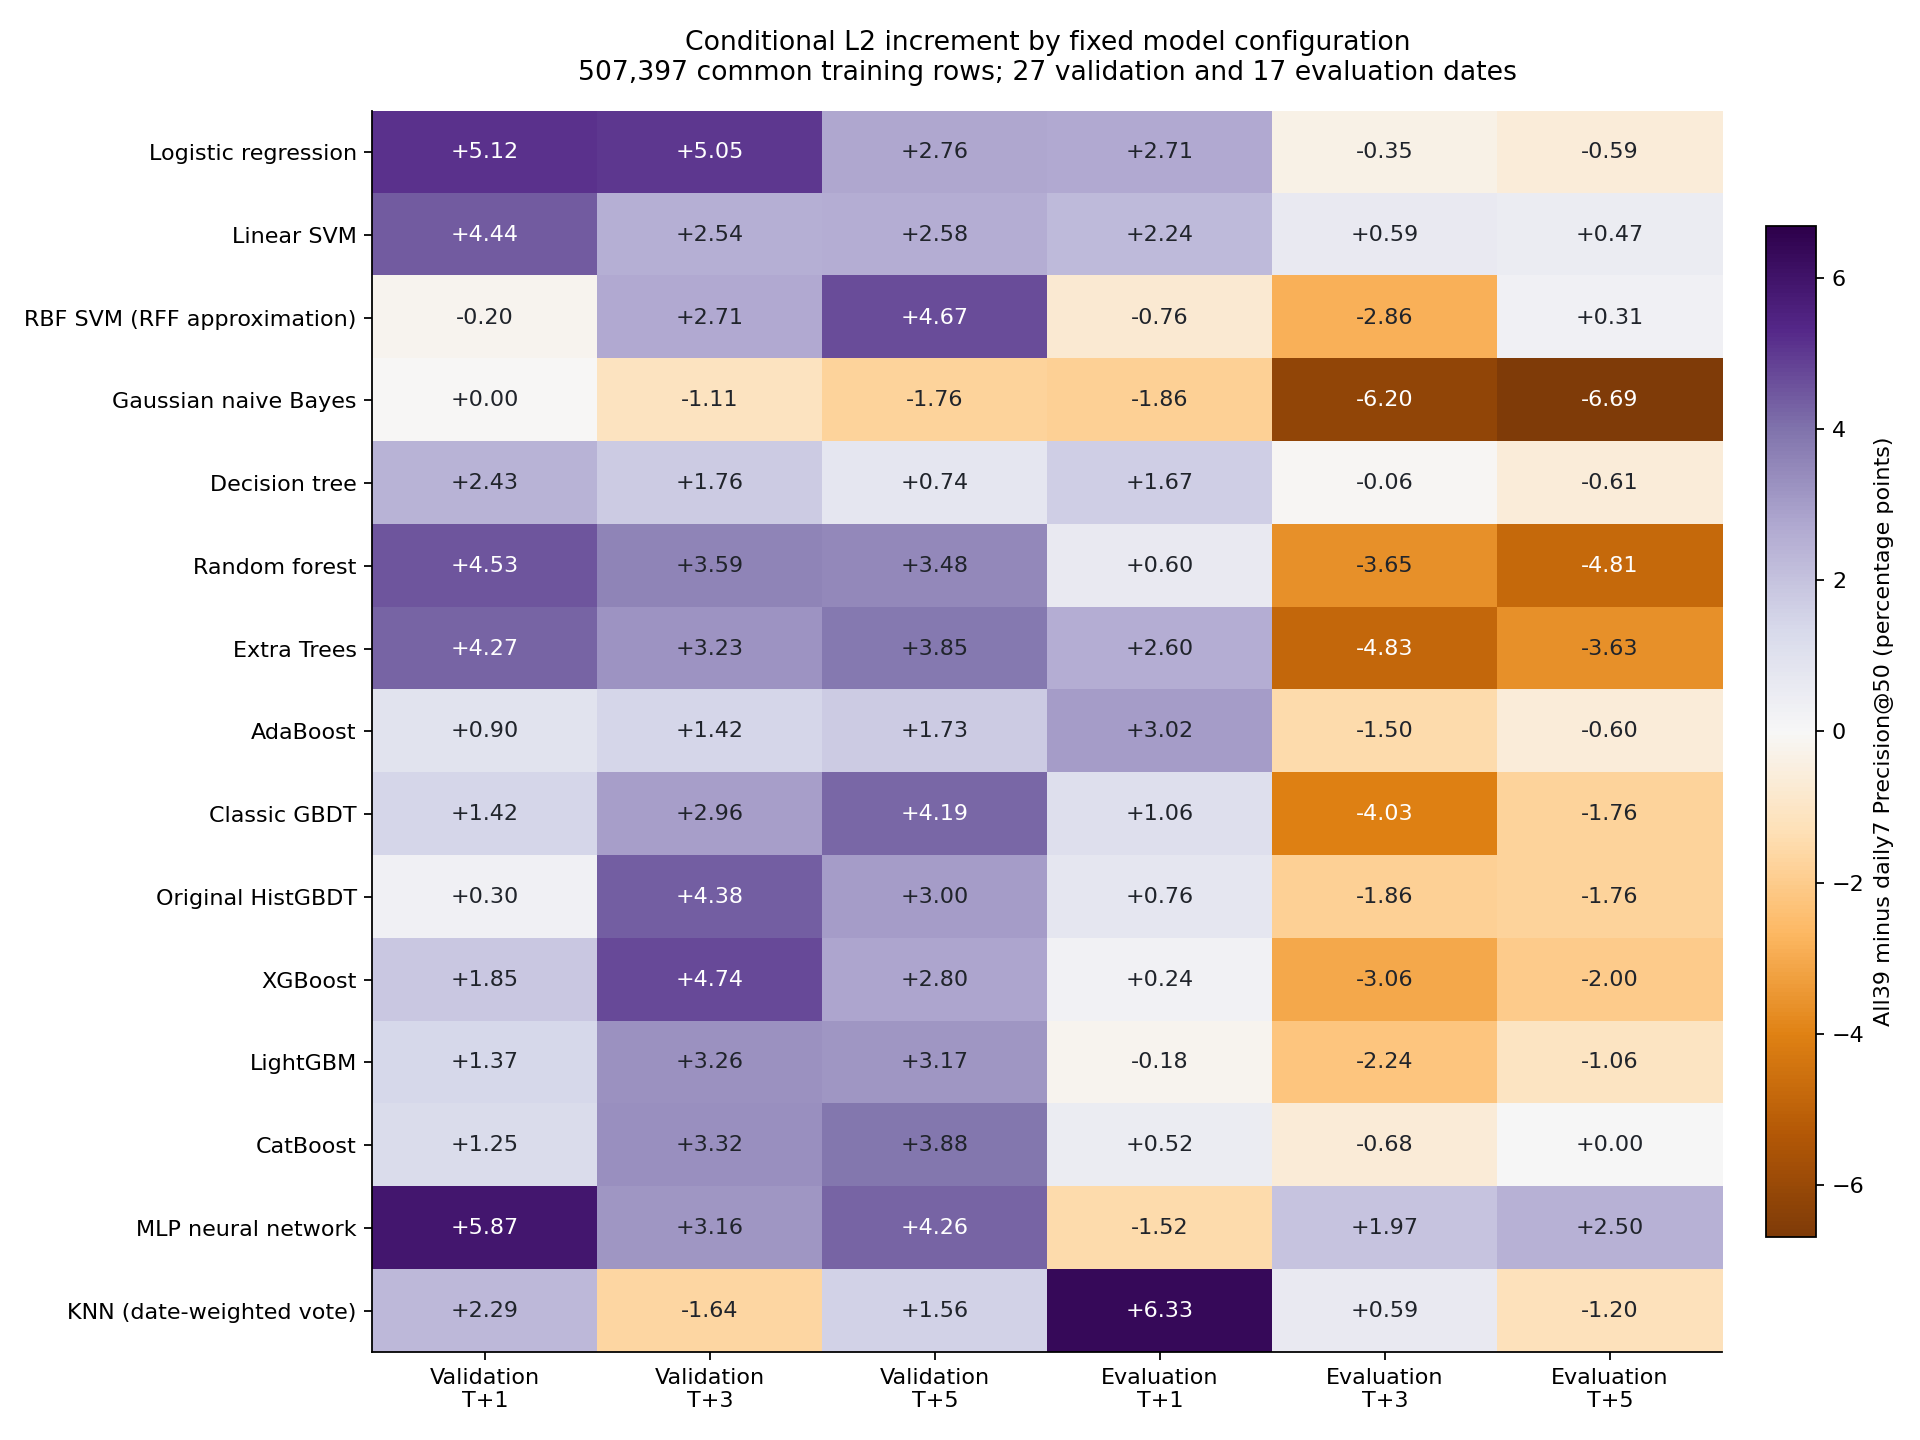

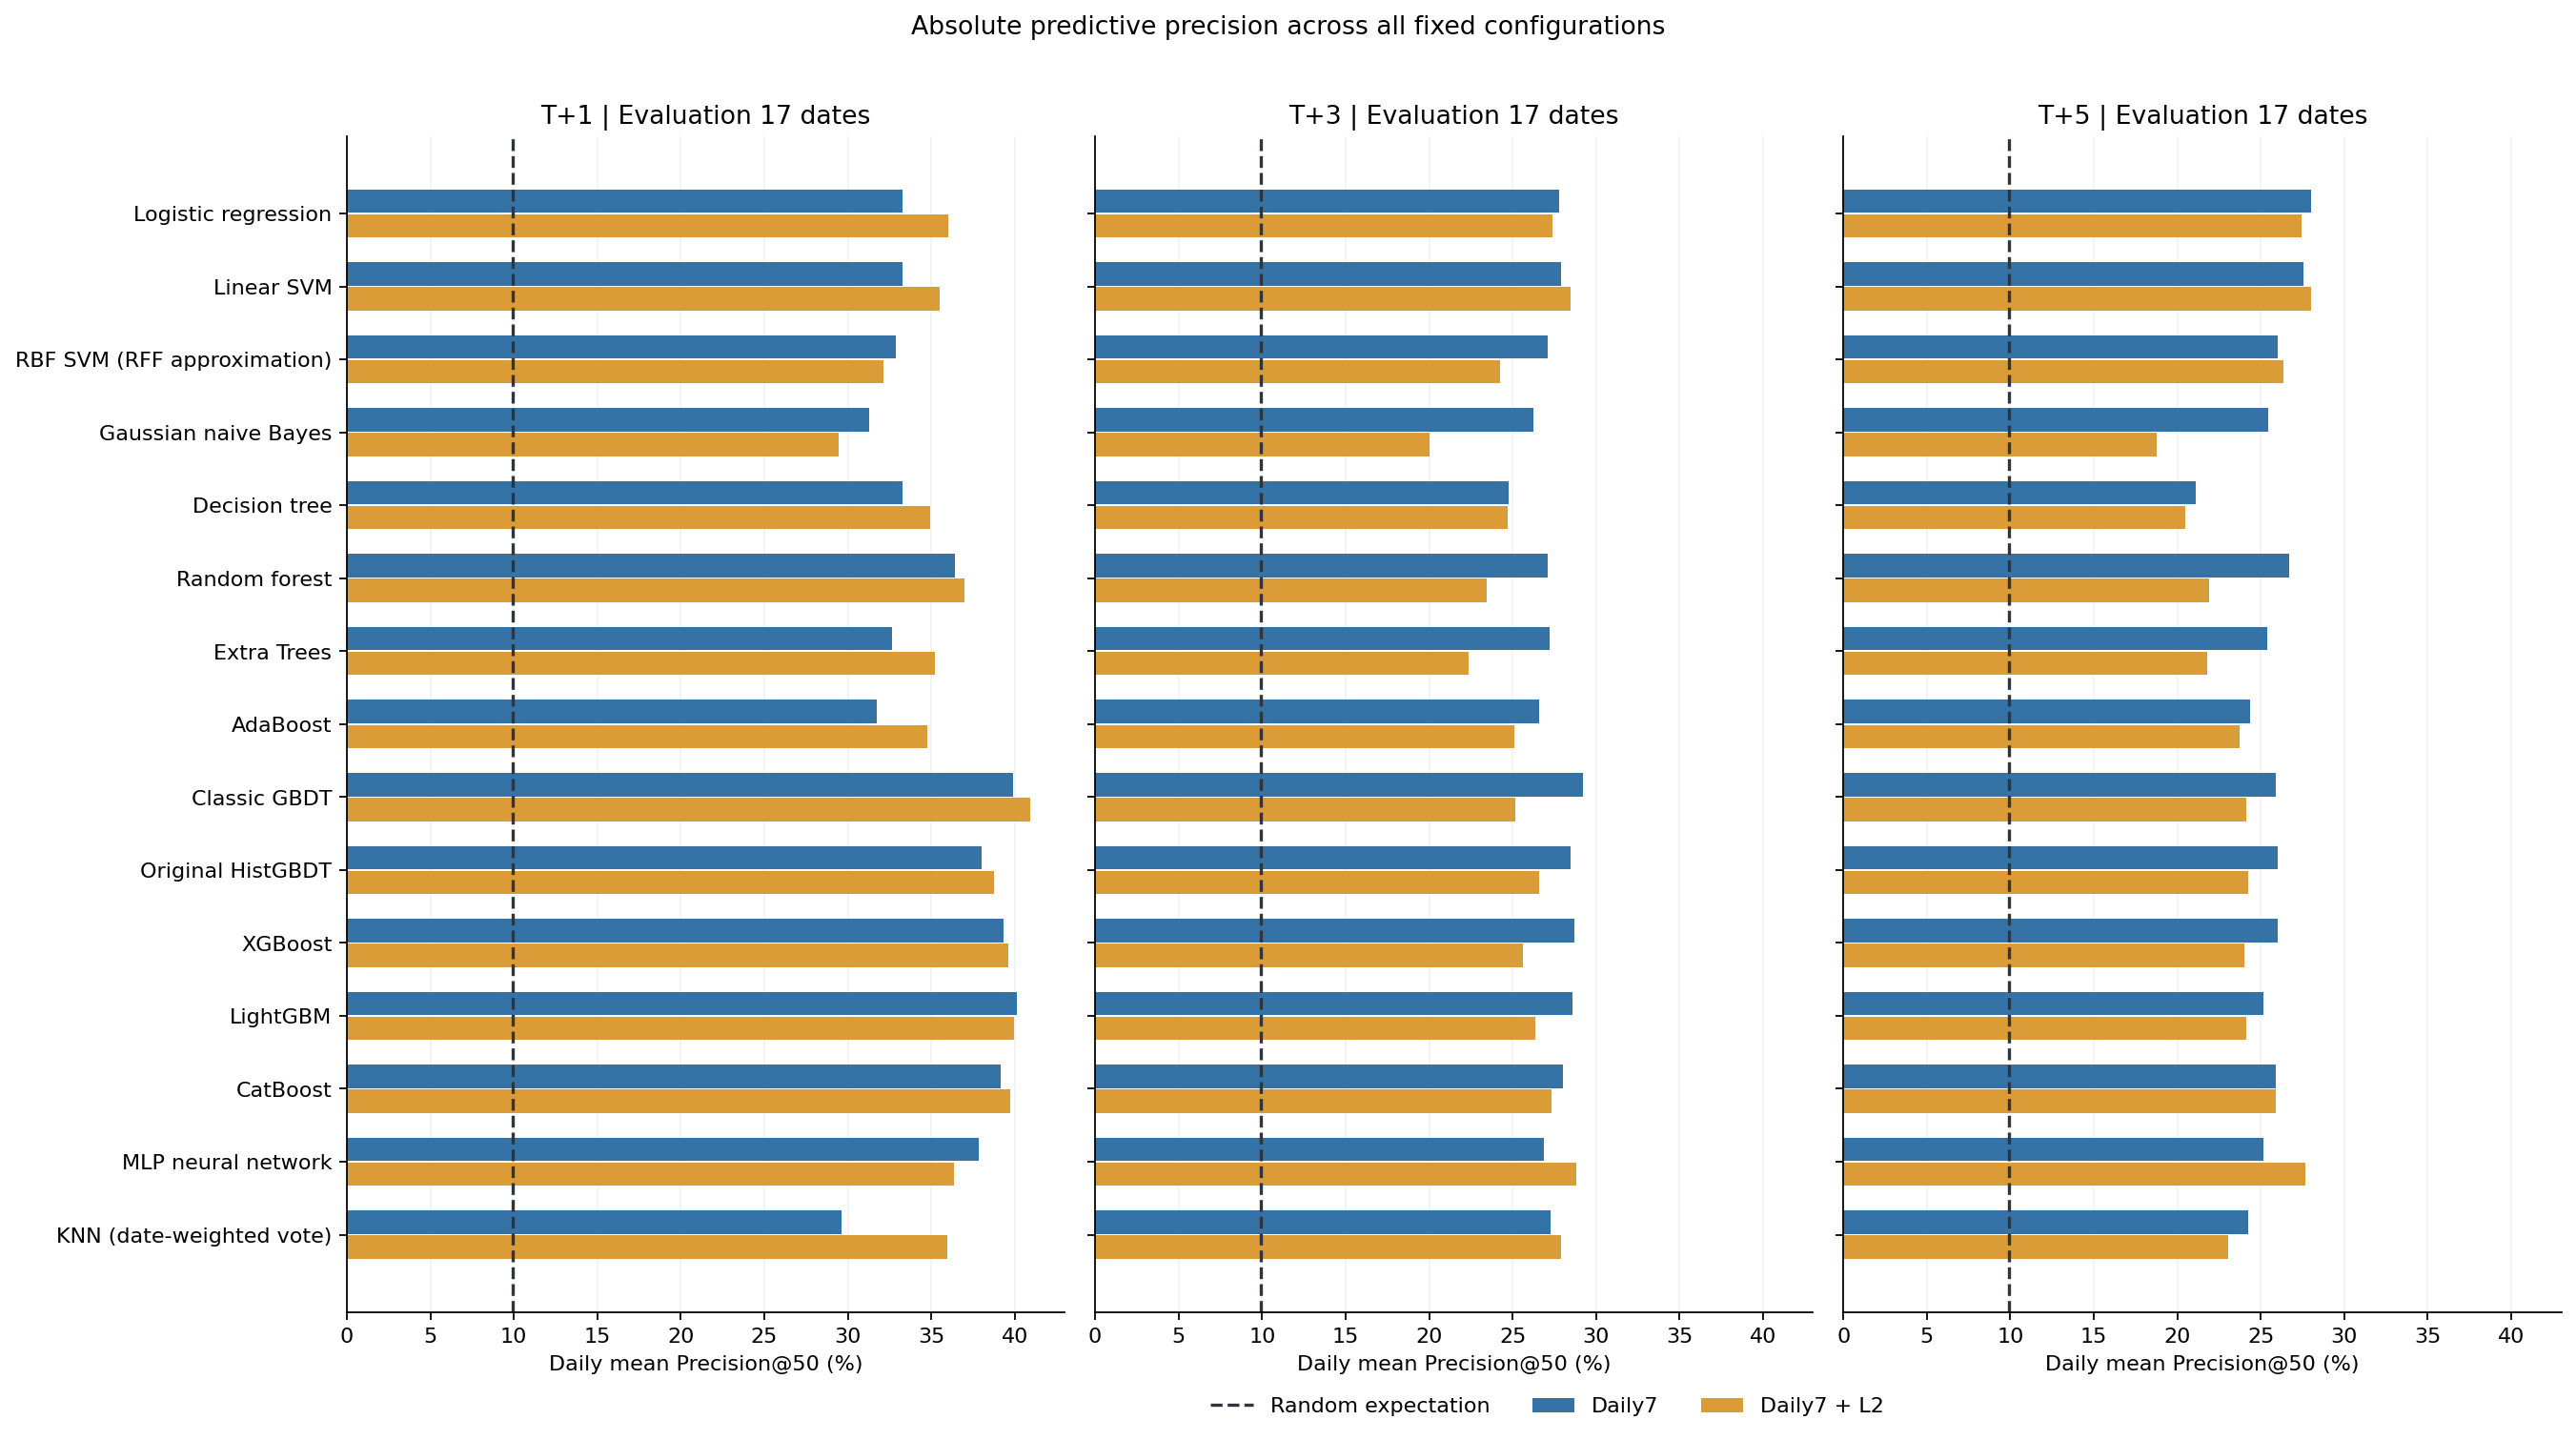

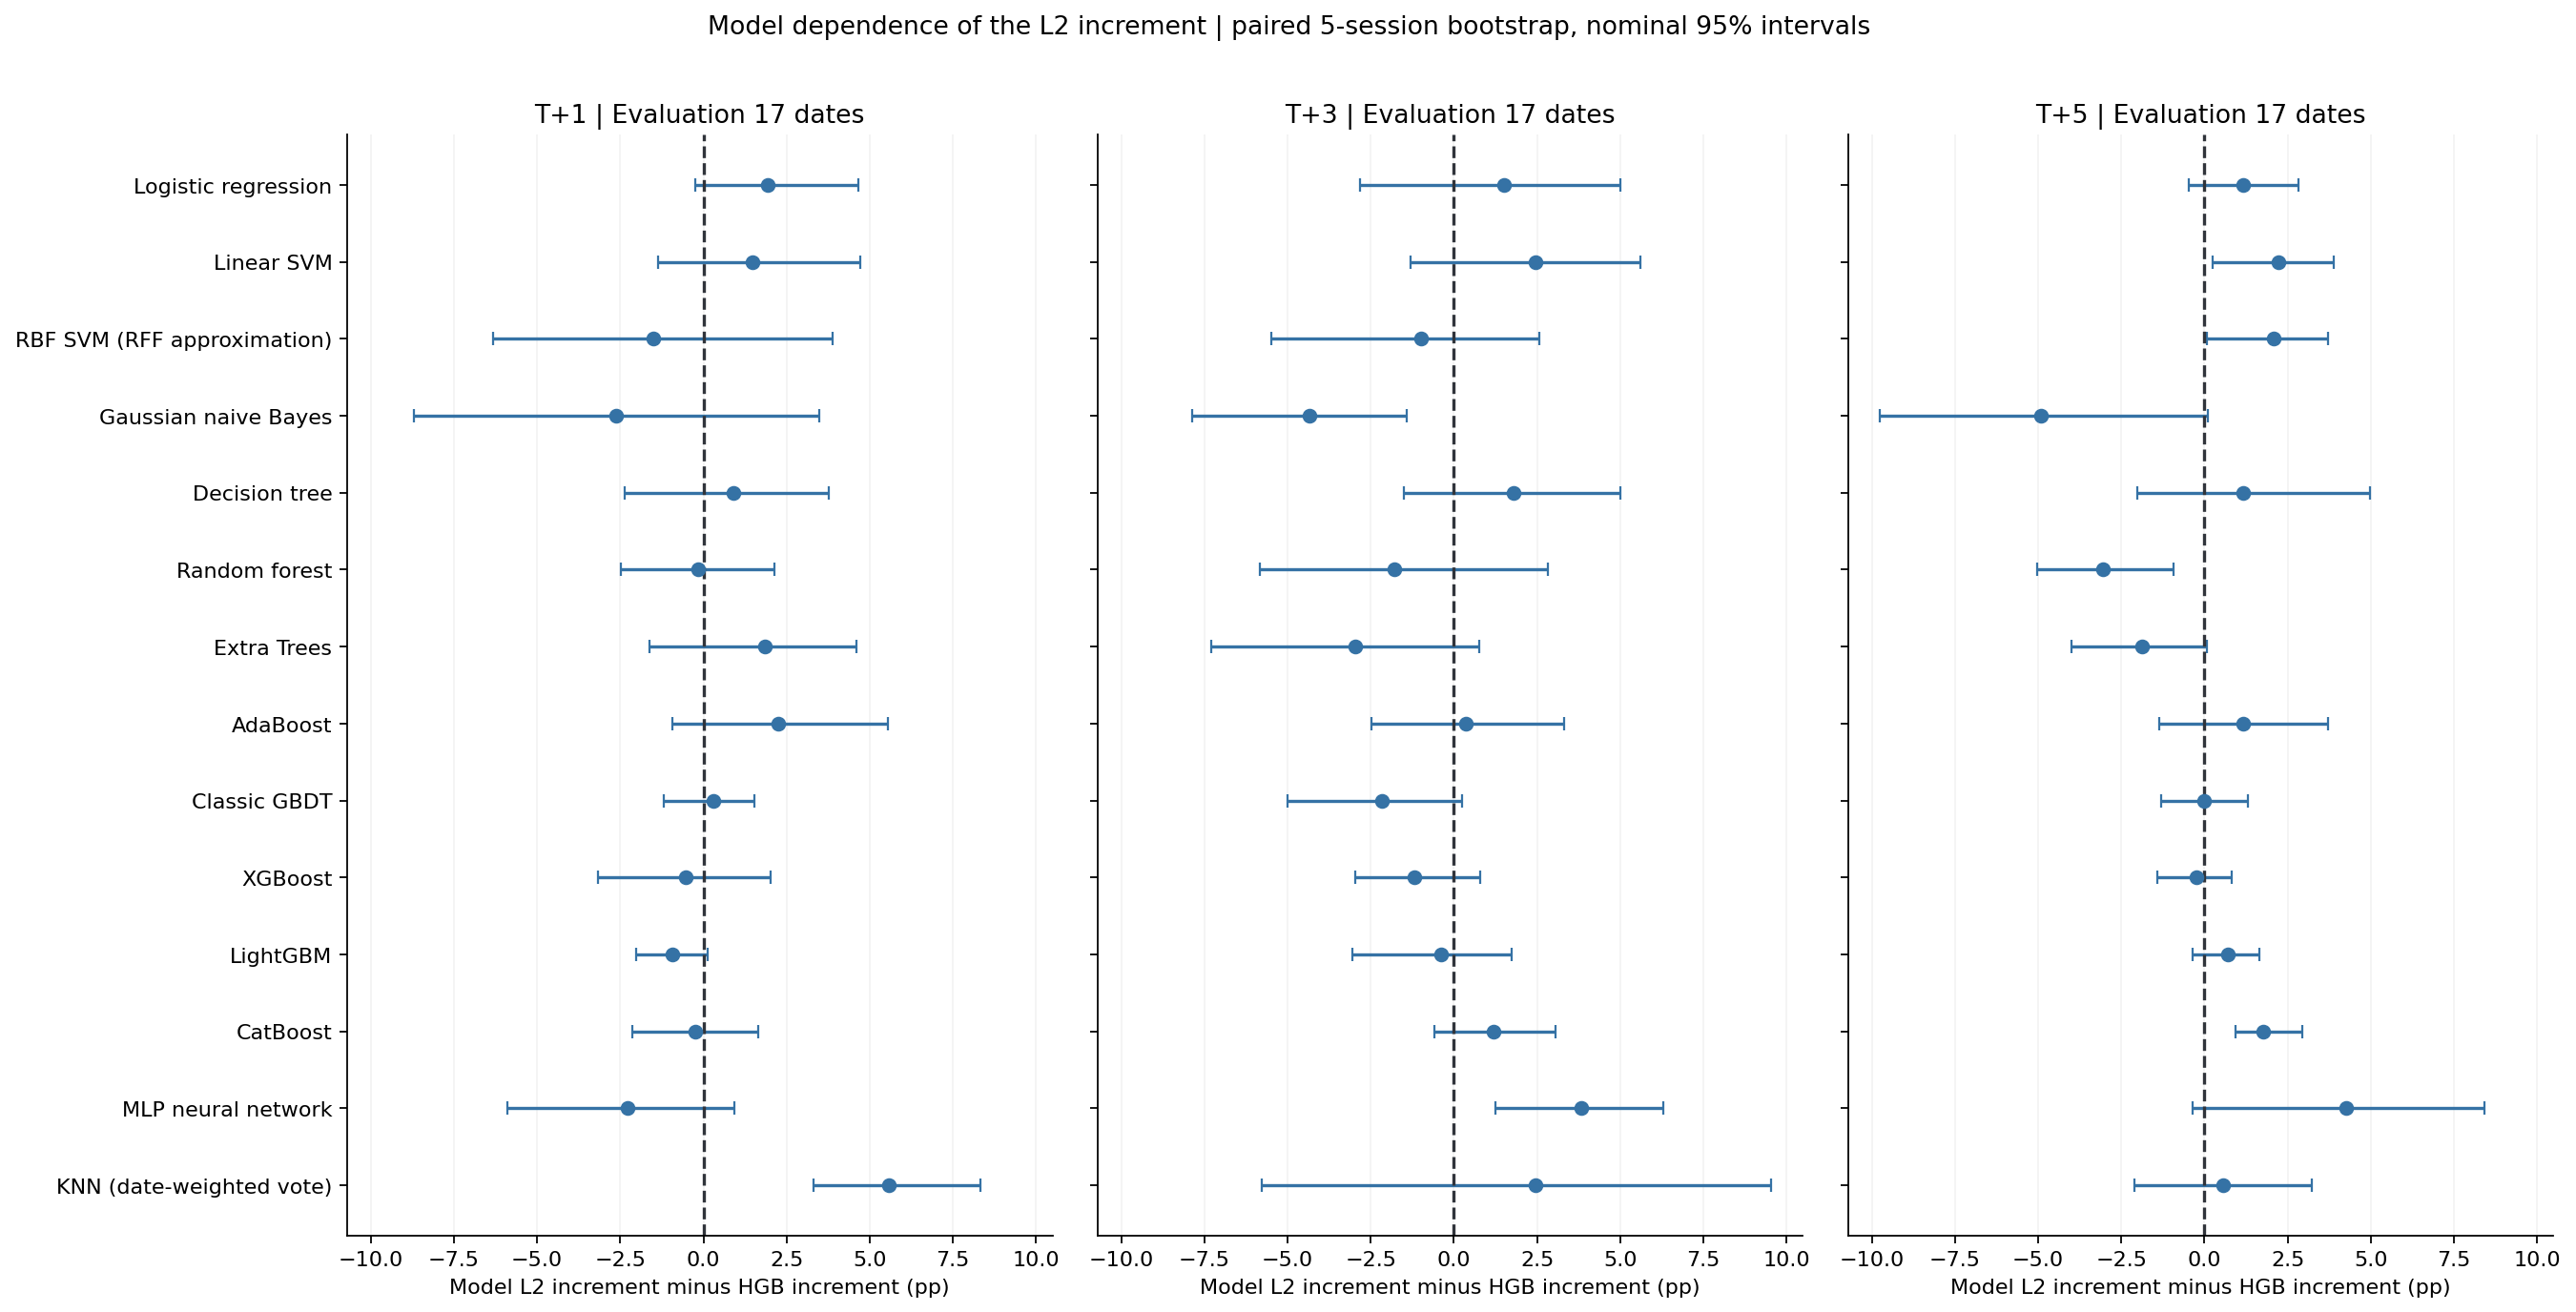

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white'})
order=list(protocol['models'])
names=[protocol['models'][m]['label'] for m in order]
primary=comparison.loc[comparison.block_sessions.eq(5)]
values=primary.pivot(index='model',columns=['stage','horizon'],values='mean_difference').reindex(order)
columns=[(s,h) for s in protocol['stages'] for h in protocol['horizons']]
array=values.reindex(columns=columns).to_numpy()*100
limit=max(1,float(np.nanmax(np.abs(array))))
fig,ax=plt.subplots(figsize=(12,9))
im=ax.imshow(array,cmap='PuOr',norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),aspect='auto')
ax.set_xticks(range(6),[f'{s.title()}\nT+{h}' for s,h in columns])
ax.set_yticks(range(len(order)),names)
for i in range(len(order)):
    for j in range(6):
        v=array[i,j]
        v=0.0 if abs(v)<.005 else v
        ax.text(j,i,'missing' if np.isnan(v) else f'{v:+.2f}',ha='center',va='center',color='white' if np.isfinite(v) and abs(v)>limit*.6 else '#20242b')
ax.set_title('Conditional L2 increment by fixed model configuration\n507,397 common training rows; 27 validation and 17 evaluation dates',pad=14)
fig.colorbar(im,ax=ax,label='All39 minus daily7 Precision@50 (percentage points)',fraction=.035,pad=.03)
fig.tight_layout()
fig.savefig(evidence/'figures/l2-increments.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/l2-increments.png')))

fig,axes=plt.subplots(1,3,figsize=(17,9),sharey=True,sharex=True)
y=np.arange(len(order))
for ax,h in zip(axes,protocol['horizons']):
    frame=summary.loc[(summary.stage=='evaluation')&(summary.horizon==h)].pivot(index='model',columns='group',values='precision').reindex(order)*100
    ax.barh(y-.17,frame.daily7,height=.32,label='Daily7',color='#3572a5')
    ax.barh(y+.17,frame.all39,height=.32,label='Daily7 + L2',color='#db9b36')
    ax.axvline(random_by_period.loc[(h,'evaluation')]*100,color='#30343b',linestyle='--',label='Random expectation')
    ax.set_title(f'T+{h} | Evaluation 17 dates')
    ax.set_xlabel('Daily mean Precision@50 (%)')
    ax.set_yticks(y,names)
    ax.grid(axis='x',alpha=.15)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='lower center', bbox_to_anchor=(.60, -.025), ncol=3, frameon=False)
axes[0].set_xlim(left=0)
fig.suptitle('Absolute predictive precision across all fixed configurations',y=1.01)
fig.tight_layout()
fig.savefig(evidence/'figures/evaluation-precision.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(evidence/'figures/evaluation-precision.png')))

fig,axes=plt.subplots(1,3,figsize=(17,8.5),sharey=True,sharex=True)
other=[m for m in order if m!='hist_gbdt']
for ax,h in zip(axes,protocol['horizons']):
    frame=interaction.loc[(interaction.stage=='evaluation')&(interaction.horizon==h)&(interaction.block_sessions==5)].set_index('model').reindex(other)
    center=frame.mean_model_interaction.to_numpy()*100
    low=frame.ci95_lower.to_numpy()*100
    high=frame.ci95_upper.to_numpy()*100
    ax.errorbar(center,np.arange(len(other)),xerr=np.vstack([center-low,high-center]),fmt='o',color='#3572a5',capsize=3)
    ax.axvline(0,color='#30343b',linestyle='--')
    ax.set_title(f'T+{h} | Evaluation 17 dates')
    ax.set_xlabel('Model L2 increment minus HGB increment (pp)')
    ax.set_yticks(np.arange(len(other)),[protocol['models'][m]['label'] for m in other])
    ax.grid(axis='x',alpha=.15)
axes[0].invert_yaxis()
fig.suptitle('Model dependence of the L2 increment | paired 5-session bootstrap, nominal 95% intervals',y=1.01)
fig.tight_layout()
fig.savefig(evidence/'figures/model-interactions.png',dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(evidence/'figures/model-interactions.png')))

## 9. 完成核验与结果保留

检查输入守恒、输出数量、候选完整性及拟合状态；源码、环境、协议和模型绑定本次证据。
所有未完成或不收敛配置保留，完整对照验收不会把它们算作成功。
本轮没有新增独立预测日期，没有变更H08真实前向候选，没有正式模型采用或部署。

In [9]:
for entry in manifest:
    assert hashlib.sha256((evidence/entry['path']).read_bytes()).hexdigest()==entry['sha256']
for relative,specification in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/relative).read_bytes()).hexdigest()==specification['sha256']
assert len(fit_records)==90
status_counts=pd.Series([r['status'] for r in fit_records]).value_counts().to_dict()
completed=sum(r['status'] in ['complete','reused','unconverged'] for r in fit_records)
assert len(metrics)==completed*44 and len(selections)==len(metrics)
verification={'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest(),'base_commit':protocol['base_commit'],
              'common_fit_rows':len(fit_table),'common_train_days':102,'fit_key_sha256':fit_key_hash,
              'model_configurations':15,'planned_model_outputs':90,'model_status_counts':status_counts,
              'complete_converged_comparison':all(r['status'] in ['complete','reused'] for r in fit_records),
              'input_files_verified':len(manifest),'source_files_verified':len(source_manifest),
              'input_source_hashes_unchanged':True,'same_training_rows_targets_weights':True,'training_labels_mature':True,
              'future_labels_do_not_change_training_or_inference':True,'anchor_score_rows_exact':6*219985,
              'model_days_independently_evaluated':len(metrics),'completed_prediction_rows':completed*219985,
              'all_learned_model_prediction_reloads_exact':all(r.get('replay_exact',False) for r in fit_records if r['model'] not in ['hist_gbdt','knn'] and r['status']!='failed'),
              'knn_full_scores_from_reloaded_indexes_and_target_bundles':all(r.get('reloaded_index_full_inference',False) and r.get('target_bundle_replay_exact',False) for r in fit_records if r['model']=='knn'),
              'random_baseline_independently_recovered':True,'all_planned_configurations_retained':True,
              'new_independent_prediction_dates':0,'official_storage_writes':False,'prospective_model_replacement':False,
              'both_periods_nominal_passes':criteria.loc[criteria.both_periods_nominal,['model','horizon']].to_dict('records'),
              'both_periods_family_adjusted_passes':criteria.loc[criteria.both_periods_adjusted,['model','horizon']].to_dict('records')}
(evidence/'verification.json').write_text(json.dumps(verification,ensure_ascii=False,indent=2)+'\n')
print(json.dumps(verification,ensure_ascii=False,indent=2))

{
  "protocol_sha256": "52310d16f46e8748bc20f322769dd941c47c20a9c95a372ad197bc43cfd46b97",
  "base_commit": "76c25a279685b6961cda69143f542e8ec3936f51",
  "common_fit_rows": 507397,
  "common_train_days": 102,
  "fit_key_sha256": "1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04",
  "model_configurations": 15,
  "planned_model_outputs": 90,
  "model_status_counts": {
    "complete": 84,
    "reused": 6
  },
  "complete_converged_comparison": true,
  "input_files_verified": 175,
  "source_files_verified": 169,
  "input_source_hashes_unchanged": true,
  "same_training_rows_targets_weights": true,
  "training_labels_mature": true,
  "future_labels_do_not_change_training_or_inference": true,
  "anchor_score_rows_exact": 1319910,
  "model_days_independently_evaluated": 3960,
  "completed_prediction_rows": 19798650,
  "all_learned_model_prediction_reloads_exact": true,
  "knn_full_scores_from_reloaded_indexes_and_target_bundles": true,
  "random_baseline_independently_recovere